# SCSA – So sánh các phương pháp Neural Style Transfer

Notebook này chạy và so sánh lần lượt các phương pháp NST, từ cổ điển đến hiện đại:

| # | Phương pháp | Loại | Năm |
|---|-------------|------|-----|
| ① | **Gatys et al.** | Optimization-based | 2016 |
| ② | AdaIN | Feed-forward | 2017 |
| ③ | SANet / SSA | Attention-based | 2019 |
| ④ | **SCSA** | Semantic-aware | — |

Mỗi phương pháp được đánh giá theo 2 tiêu chí:
- 🖼️ **Chất lượng ảnh đầu ra** (hiển thị trực quan)
- ⏱️ **Hiệu năng** (tổng thời gian, ms/step, peak RAM)

---
## 0 · Cài đặt & ảnh đầu vào

In [149]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

from gatys_nst import get_optimal_device, run_gatys, plot_gatys_analysis

device = get_optimal_device()
print(f"Thiết bị: {device}")

CONTENT_IMG = "img/yosemite.jpg"
STYLE_IMG   = "img/yosemite_paint.jpg"

# Gom kết quả mọi phương pháp → so sánh ở cuối
benchmark_records = []

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Thiết bị: mps


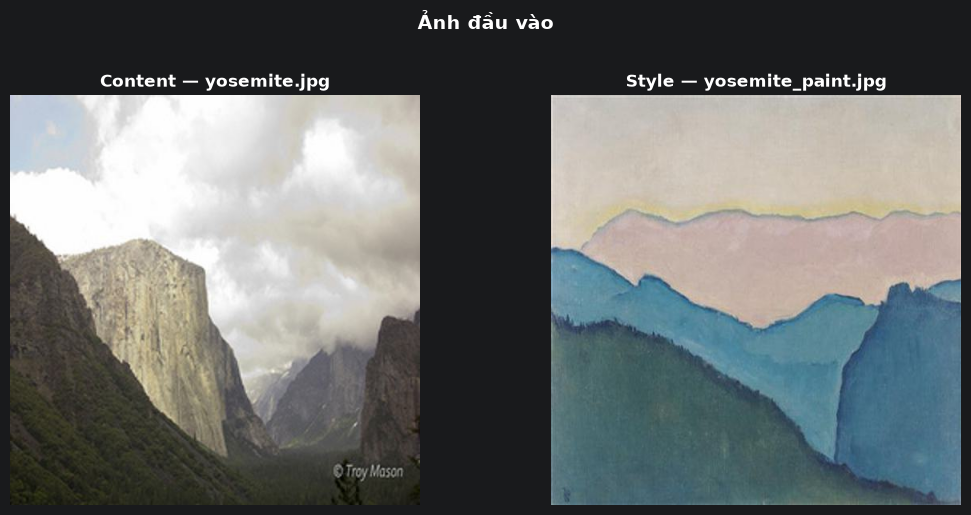

In [150]:
# Preview ảnh đầu vào
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, path, label in zip(
    axes,
    [CONTENT_IMG,               STYLE_IMG],
    ["Content — yosemite.jpg",  "Style — yosemite_paint.jpg"],
):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(label, fontsize=12, fontweight="bold")
    ax.axis("off")
plt.suptitle("Ảnh đầu vào", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

---
## ① Gatys et al. (2016) — Optimization-based NST

**Ý tưởng cốt lõi:** Tối ưu hoá trực tiếp pixel ảnh đầu ra sao cho feature của nó, trích từ VGG-19, khớp đồng thời với ảnh content và tranh style.

```
Loss = α · L_content(conv4_2)  +  β · L_style(Gram matrices × 5 layers)  +  γ · L_TV
```

**Điểm mạnh:** chất lượng cao, không cần train lại.  
**Điểm yếu:** mỗi ảnh phải tối ưu từ đầu → **rất chậm** (hàng chục giây đến vài phút).

### Cấu hình thí nghiệm
| | L-BFGS | Adam |
|---|---|---|
| Theo paper | ✅ | ❌ |
| Steps | 300 | 300 |
| Ghi chú | hội tụ nhanh hơn mỗi step | nhẹ hơn RAM/step, dễ tune |

[Gatys-LBFGS | MPS] Step 001/300 | Content: 0.000 | Style: 5.961 | Total: 5.961
[Gatys-LBFGS | MPS] Step 050/300 | Content: 0.204 | Style: 0.357 | Total: 0.561
[Gatys-LBFGS | MPS] Step 100/300 | Content: 0.161 | Style: 0.179 | Total: 0.340
[Gatys-LBFGS | MPS] Step 150/300 | Content: 0.146 | Style: 0.118 | Total: 0.264
[Gatys-LBFGS | MPS] Step 200/300 | Content: 0.139 | Style: 0.106 | Total: 0.246
[Gatys-LBFGS | MPS] Step 250/300 | Content: 0.136 | Style: 0.102 | Total: 0.238
[Gatys-LBFGS | MPS] Step 300/300 | Content: 0.134 | Style: 0.099 | Total: 0.233


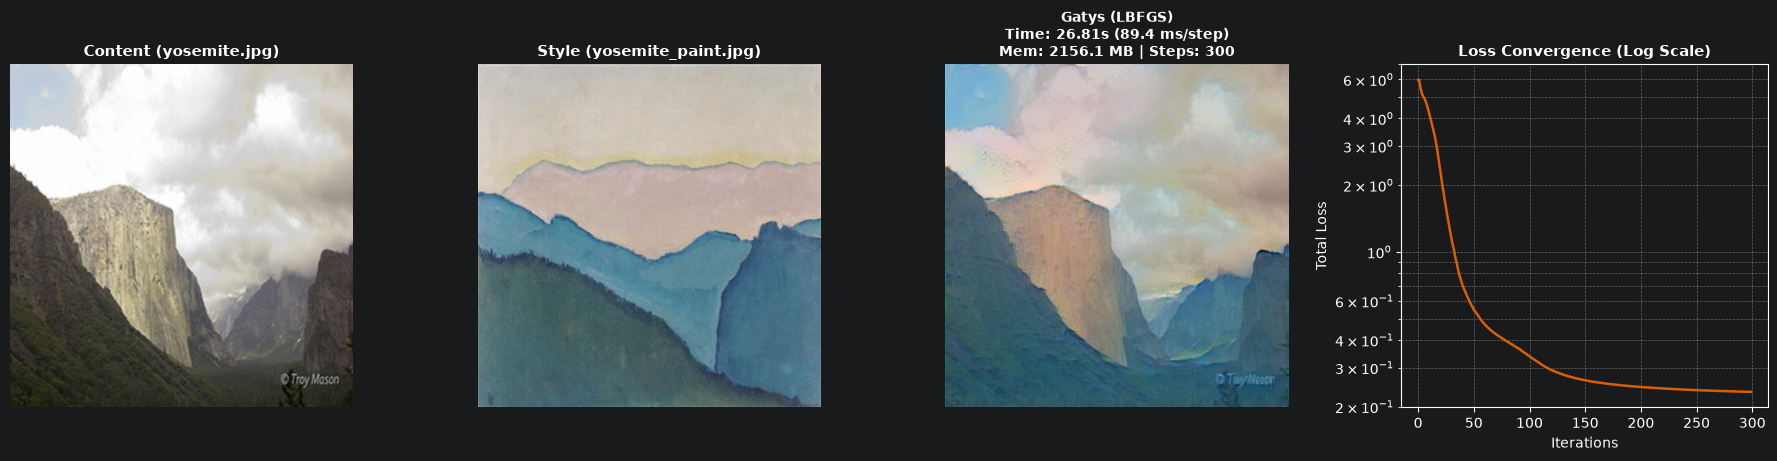

In [151]:
# ── Gatys · L-BFGS (theo paper gốc) ───────────────────────────────────
gatys_lbfgs = run_gatys(
    content_path   = CONTENT_IMG,
    style_path     = STYLE_IMG,
    img_size       = 512,
    steps          = 300,
    alpha          = 1.0,
    beta           = 1e6,
    gamma          = 1e-3,
    optimizer_type = "lbfgs",
    verbose_every  = 50,
    device         = device,
)
gatys_lbfgs.output_image.save("img/yosemite_out_gatys.jpg")
benchmark_records.append({
    'Phương pháp'   : gatys_lbfgs.method_name,
    'Thời gian (ms)': round(gatys_lbfgs.inference_time_sec * 1000, 1),
    'Peak RAM (MB)' : round(gatys_lbfgs.peak_memory_mb, 0),
    'Feed-forward'  : '✗',
    'Semantic-aware': '✗',
    'Ghi chú'       : f'{gatys_lbfgs.total_steps} steps',
})

plot_gatys_analysis(
    CONTENT_IMG, STYLE_IMG, gatys_lbfgs,
    save_path="img/yosemite_fig_gatys.png",
)

[Gatys-ADAM | MPS] Step 001/300 | Content: 0.000 | Style: 5.961 | Total: 5.961
[Gatys-ADAM | MPS] Step 050/300 | Content: 0.169 | Style: 0.716 | Total: 0.886
[Gatys-ADAM | MPS] Step 100/300 | Content: 0.147 | Style: 0.223 | Total: 0.371
[Gatys-ADAM | MPS] Step 150/300 | Content: 0.143 | Style: 0.140 | Total: 0.283
[Gatys-ADAM | MPS] Step 200/300 | Content: 0.134 | Style: 0.121 | Total: 0.255
[Gatys-ADAM | MPS] Step 250/300 | Content: 0.131 | Style: 0.108 | Total: 0.239
[Gatys-ADAM | MPS] Step 300/300 | Content: 0.130 | Style: 0.104 | Total: 0.234


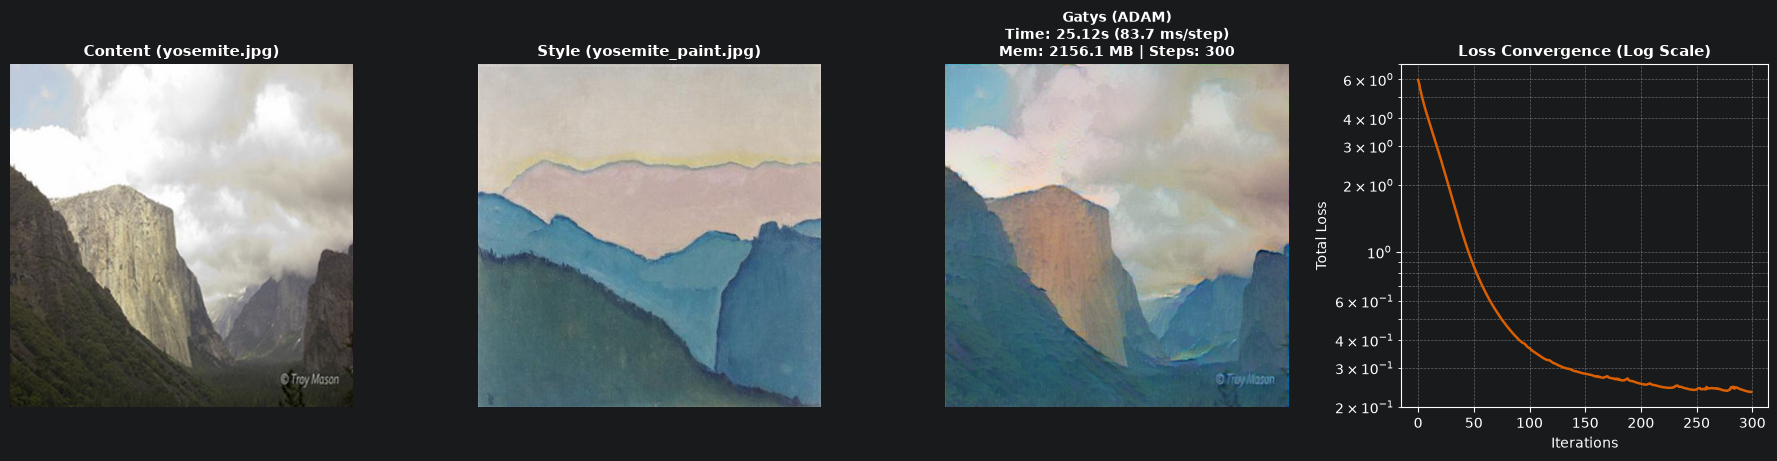

In [152]:
# ── Gatys · Adam (so sánh tốc độ) ──────────────────────────────────
gatys_adam = run_gatys(
    content_path   = CONTENT_IMG,
    style_path     = STYLE_IMG,
    img_size       = 512,
    steps          = 300,
    alpha          = 1.0,
    beta           = 1e6,
    gamma          = 1e-3,
    optimizer_type = "adam",
    lr             = 0.03,
    verbose_every  = 50,
    device         = device,
)
gatys_adam.output_image.save("img/yosemite_out_gatys_adam.jpg")
benchmark_records.append({
    'Phương pháp'   : gatys_adam.method_name,
    'Thời gian (ms)': round(gatys_adam.inference_time_sec * 1000, 1),
    'Peak RAM (MB)' : round(gatys_adam.peak_memory_mb, 0),
    'Feed-forward'  : '✗',
    'Semantic-aware': '✗',
    'Ghi chú'       : f'{gatys_adam.total_steps} steps',
})

plot_gatys_analysis(
    CONTENT_IMG, STYLE_IMG, gatys_adam,
    save_path="img/yosemite_fig_gatys_adam.png",
)

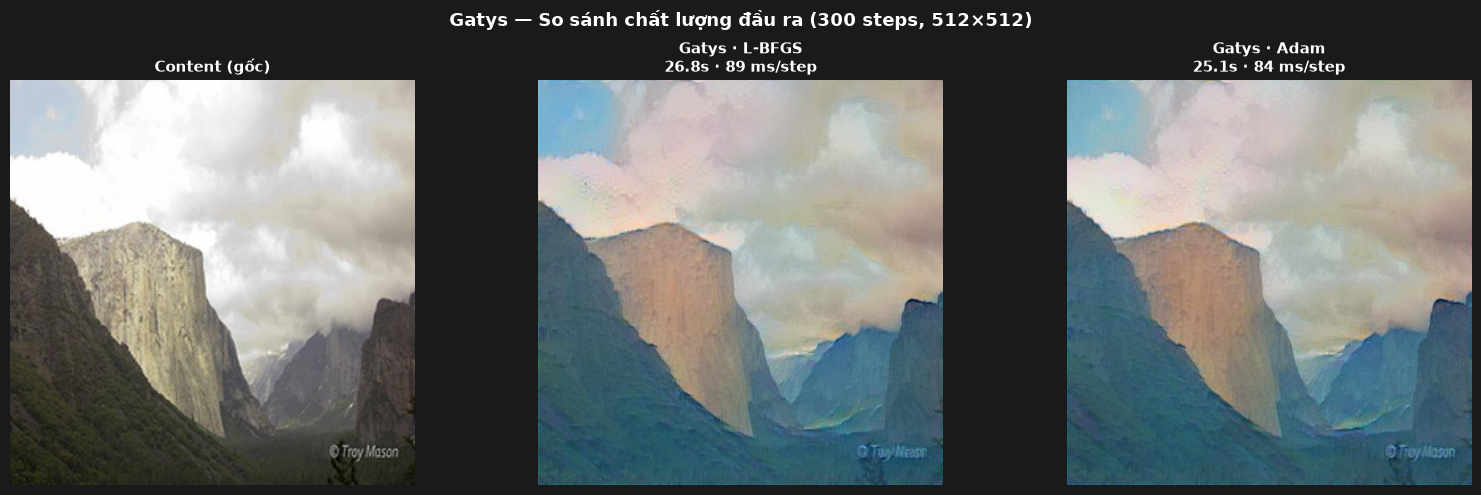

In [153]:
# ── So sánh chất lượng đầu ra: L-BFGS vs Adam ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
panels = [
    (CONTENT_IMG,                        "Content (gốc)"),
    ("img/yosemite_out_gatys.jpg",
     f"Gatys · L-BFGS\n"
     f"{gatys_lbfgs.inference_time_sec:.1f}s · {gatys_lbfgs.time_per_step_ms:.0f} ms/step"),
    ("img/yosemite_out_gatys_adam.jpg",
     f"Gatys · Adam\n"
     f"{gatys_adam.inference_time_sec:.1f}s · {gatys_adam.time_per_step_ms:.0f} ms/step"),
]
for ax, (path, label) in zip(axes, panels):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(label, fontsize=11, fontweight="bold")
    ax.axis("off")
plt.suptitle(
    "Gatys — So sánh chất lượng đầu ra (300 steps, 512×512)",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.show()

---
## ② AdaIN (2017) — Feed-forward NST

**Ý tưởng cốt lõi:** Thay vì tối ưu trực tiếp trên pixel (như Gatys),
AdaIN *dịch chuyển thống kê feature* trong một phép tính duy nhất, rồi cho qua decoder đã train:

$$\text{AdaIN}(x,y) = \sigma(y)\cdot\frac{x - \mu(x)}{\sigma(x)} + \mu(y)$$

- **x** = feature content tại relu4\_1  
- **y** = feature style tại relu4\_1  
- Chỉ chuyển $(\mu, \sigma)$ per-channel — không có Gram matrix, không có tối ưu

**Điểm mạnh:** Nhanh hơn Gatys **~300x** — single forward pass.  
**Điểm yếu:** Chất lượng đôi khi mỏng hơn; không biết ngưỡng semantic. Cần train decoder.

**Tính năng độc đáo so với Gatys:** điều chỉnh cường độ style tức thời qua α — không cần chạy lại.

### Cấu hình thí nghiệm
| | AdaIN |
|---|---|
| Encoder | VGG-19 normalised (naoto0804), up to relu4\_1 |
| Decoder | Mirror encoder, pre-trained (decoder.pth) |
| Bước tham chiếu | **1** (single forward pass) |
| Input range | **[0, 1]** (không normalize ImageNet, khác Gatys) |

In [154]:
# ── Tải pre-trained weights (chỉ cần 1 lần, ~94 MB tổng từ GitHub) ─────────
from adain_nst import download_adain_weights
download_adain_weights()

# Nguồn: github.com/naoto0804/pytorch-AdaIN/releases/tag/v0.0.0
# weights/ sẽ chứa: vgg_normalised.pth (~80 MB) + decoder.pth (~14 MB)

  ✓ vgg_normalised.pth  (76 MB, đã có)
  ✓ decoder.pth  (13 MB, đã có)


[AdaIN | MPS] α=1.00 | 96.9 ms  (1 forward pass) | Peak RAM: 1124 MB


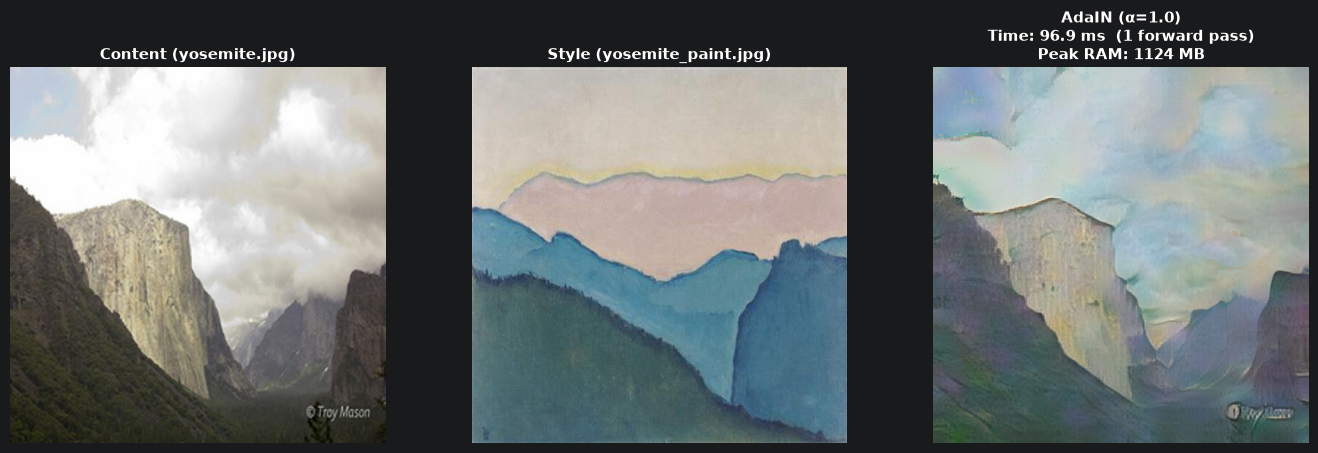

In [155]:
from adain_nst import run_adain, plot_adain_analysis

# ── AdaIN · α = 1.0 (full style transfer) ───────────────────────────
adain_res = run_adain(
    content_path = CONTENT_IMG,
    style_path   = STYLE_IMG,
    img_size     = 512,
    alpha        = 1.0,
    device       = device,
)
adain_res.output_image.save("img/yosemite_out_adain.jpg")
benchmark_records.append({
    'Phương pháp'   : adain_res.method_name,
    'Thời gian (ms)': round(adain_res.inference_time_sec * 1000, 1),
    'Peak RAM (MB)' : round(adain_res.peak_memory_mb, 0),
    'Feed-forward'  : '✓',
    'Semantic-aware': '✗',
    'Ghi chú'       : '1 forward pass',
})

plot_adain_analysis(
    CONTENT_IMG, STYLE_IMG, adain_res,
    save_path="img/yosemite_fig_adain.png",
)

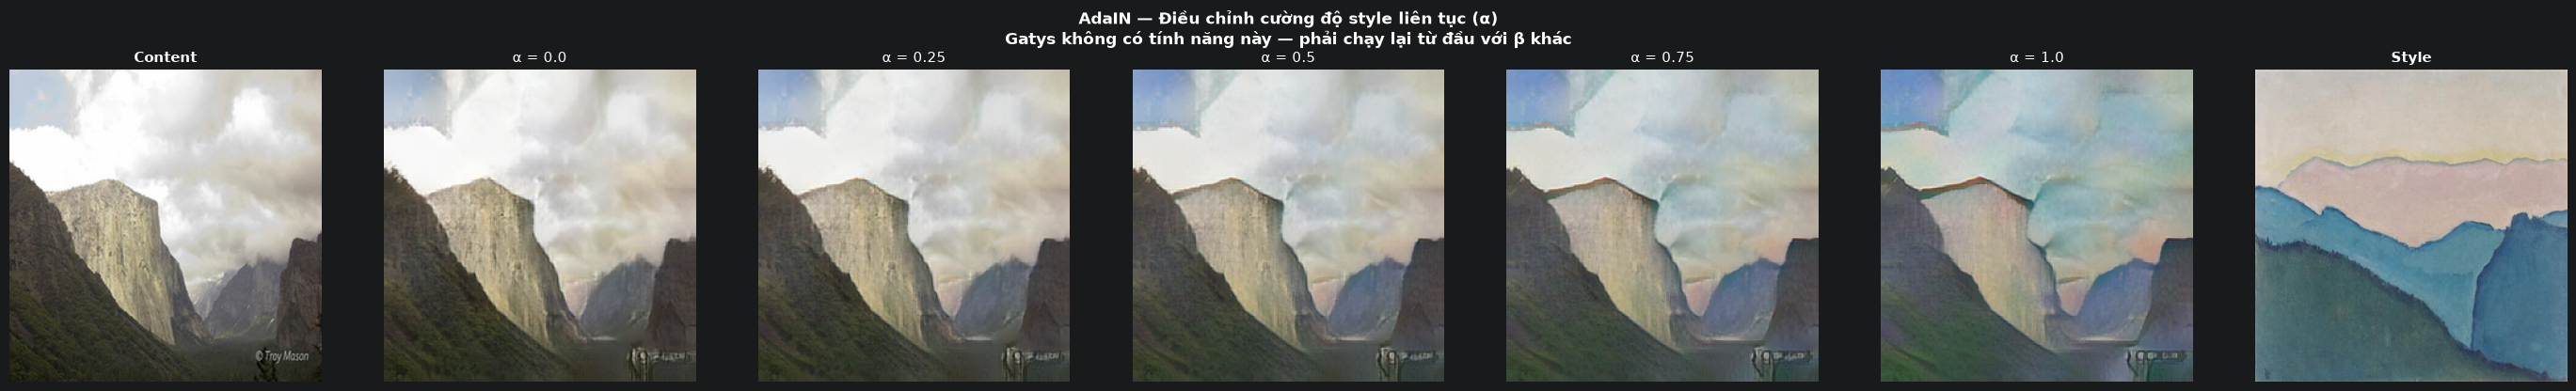

In [156]:
# ── Tính năng độc đáo: điều chỉnh α liên tục, không cần chạy lại ───────
from adain_nst import plot_adain_alpha_grid

plot_adain_alpha_grid(
    CONTENT_IMG, STYLE_IMG,
    alphas    = [0.0, 0.25, 0.5, 0.75, 1.0],
    img_size  = 256,
    device    = device,
    save_path = "img/yosemite_fig_adain_alpha.png",
)

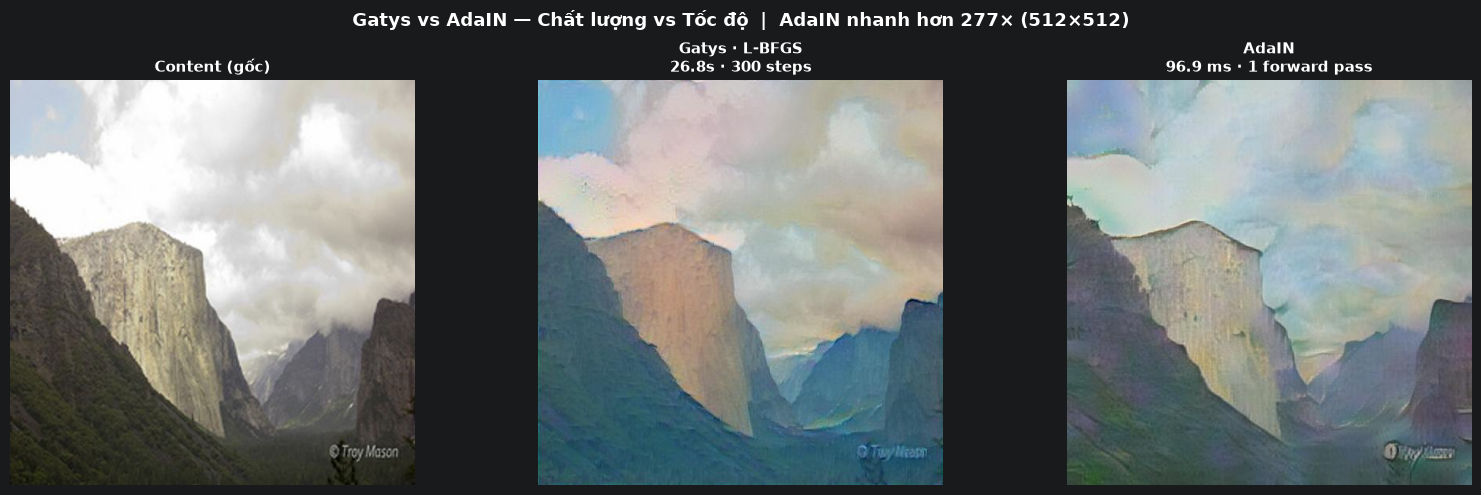

In [157]:
# ── So sánh trực quan: Gatys L-BFGS vs AdaIN ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
panels = [
    (CONTENT_IMG,
     "Content (gốc)"),
    ("img/yosemite_out_gatys.jpg",
     f"Gatys · L-BFGS\n"
     f"{gatys_lbfgs.inference_time_sec:.1f}s · {gatys_lbfgs.total_steps} steps"),
    ("img/yosemite_out_adain.jpg",
     f"AdaIN\n"
     f"{adain_res.inference_time_sec * 1000:.1f} ms · 1 forward pass"),
]
for ax, (path, label) in zip(axes, panels):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(label, fontsize=11, fontweight="bold")
    ax.axis("off")

speedup = gatys_lbfgs.inference_time_sec / adain_res.inference_time_sec
plt.suptitle(
    f"Gatys vs AdaIN — Chất lượng vs Tốc độ  |"
    f"  AdaIN nhanh hơn {speedup:.0f}× (512×512)",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.show()

---
## ③ SANet (CVPR 2019) — Style-Attentional Networks

**Ý tưởng cốt lõi:** Thay vì transfer global statistics như AdaIN,
SANet tính **cross-attention** giữa từng điểm content và toàn bộ điểm style.
Mỗi điểm content tự "hỏi" style: *tôi trông giống điểm nào nhất?*

$$F_{cs} = \operatorname{softmax}\!\left(\frac{Q K^\top}{\sqrt{C}}\right) V$$

| | AdaIN | SANet |
|---|---|---|
| Statistics | Global mean + std | Per-point attention |
| Texture matching | Gần đúng (stat) | Tốt hơn (local similarity) |
| Speed | 1 forward pass | 1 forward pass |

> **Lưu ý:** Phiên bản này dùng AdaIN weights (encoder + decoder) + SANet attention
> (non-parametric, không cần train thêm). Full SANet cần decoder riêng. Đây là demo cơ chế.


[SANet | MPS]  dual-lvl TRAINED  temp=1.00  blend=1.00  | 124.3 ms  | Peak RAM: 0 MB


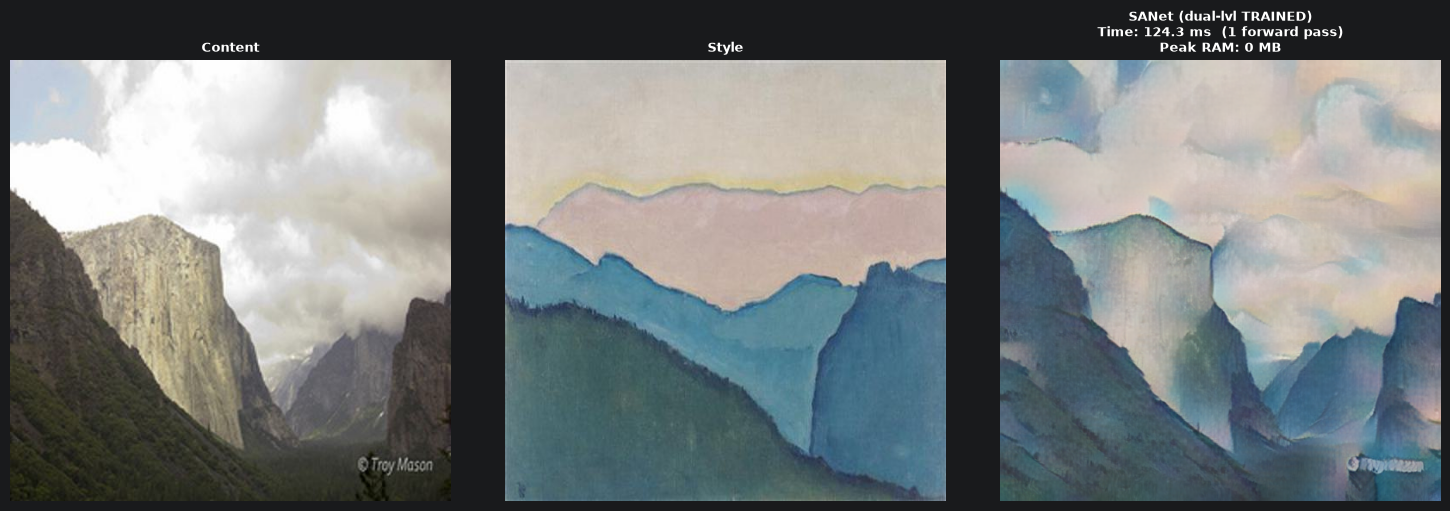

In [158]:
from sanet_nst import run_sanet, plot_sanet_analysis, plot_sanet_temperature_grid

# run_sanet tự động dùng weights/sanet/ (Yandex) nếu có,
# fallback sang single-level + AdaIN decoder nếu không.
result_sanet = run_sanet(
    content_path = CONTENT_IMG,
    style_path   = STYLE_IMG,
    img_size     = 512,
    device       = device,
)
result_sanet.output_image.save('img/yosemite_out_sanet.jpg')

plot_sanet_analysis(
    CONTENT_IMG, STYLE_IMG, result_sanet,
    save_path = 'img/yosemite_fig_sanet.png',
)
benchmark_records.append({
    'Phương pháp'   : 'SANet',
    'Thời gian (ms)': round(result_sanet.inference_time_sec * 1000, 1),
    'Peak RAM (MB)' : round(result_sanet.peak_memory_mb, 0),
    'Feed-forward'  : '✓',
    'Semantic-aware': '✗',
    'Ghi chú'       : result_sanet.method_name,
})


[SANet | MPS]  dual-lvl TRAINED  temp=0.25  blend=1.00  | 41.8 ms  | Peak RAM: 8 MB
[SANet | MPS]  dual-lvl TRAINED  temp=0.50  blend=1.00  | 28.6 ms  | Peak RAM: 0 MB
[SANet | MPS]  dual-lvl TRAINED  temp=1.00  blend=1.00  | 28.1 ms  | Peak RAM: 0 MB
[SANet | MPS]  dual-lvl TRAINED  temp=2.00  blend=1.00  | 27.8 ms  | Peak RAM: 0 MB
[SANet | MPS]  dual-lvl TRAINED  temp=4.00  blend=1.00  | 28.1 ms  | Peak RAM: 0 MB


/Users/bibeo/Desktop/SCSA/sanet_nst.py:413: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


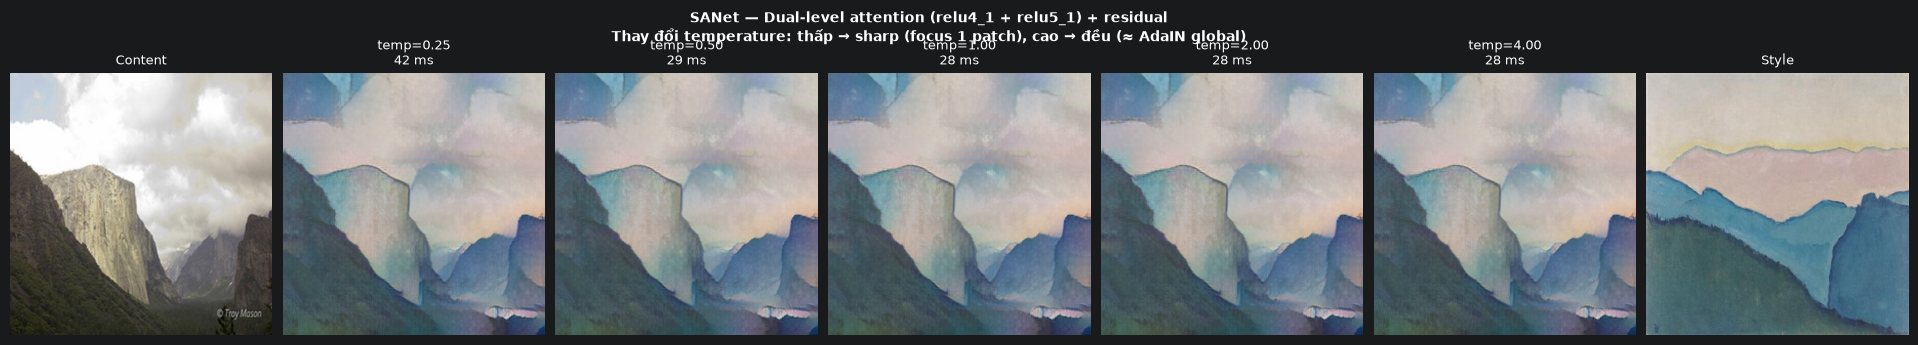

In [159]:
from sanet_nst import plot_sanet_temperature_grid

# ── Temperature grid: thấp → attention sharp, cao → đều (≈ AdaIN) ────────
plot_sanet_temperature_grid(
    CONTENT_IMG, STYLE_IMG,
    temperatures = [0.25, 0.5, 1.0, 2.0, 4.0],
    img_size     = 256,
    device       = device,
    save_path    = 'img/yosemite_fig_sanet_temp.png',
)

---
## ④ SCSA — Semantic·Continuous·Sparse·Attention

**Ý tưởng cốt lõi:** "Chỉ nhìn trong vùng cùng nhãn."
SCSA thêm **mặt nạ ngữ nghĩa** vào SANet attention: vùng da thịt chỉ lấy texture
từ vùng da thịt của style, vùng bầu trời chỉ nhìn bầu trời.

**Ba khối chính:**
- **SCA** (Semantic Continuous Attention): hỏi bằng bản đồ nhãn → mỗi vùng nhận
  trung bình tông màu của vùng cùng nhãn trong style (đều, không loang lổ)
- **S-AdaIN**: AdaIN riêng từng vùng → chuẩn hoá tông trước SSA
- **SSA** (Semantic Sparse Attention): hỏi bằng content features → top-1 patch
  giống nhất trong cùng vùng (giữ nguyên nét cọ, không nhạt nhoà)

$$F_{out} = \alpha_1 \cdot SCA + \alpha_2 \cdot SSA + F_c$$

| | SANet | SCSA |
|---|---|---|
| Attention mask | Không (full attention) | Semantic region mask |
| Texture source | Bất kỳ điểm style | Trong cùng vùng nhãn |
| Tham số mới | — | **0** (plug-and-play) |
| Hiệu ứng | Đôi khi sai vùng | Đúng vùng, nét cọ rõ |


Số vùng ngữ nghĩa: 4
Labels content unique: [0, 1, 2, 3]
Labels style   unique: [0, 1, 2, 3]


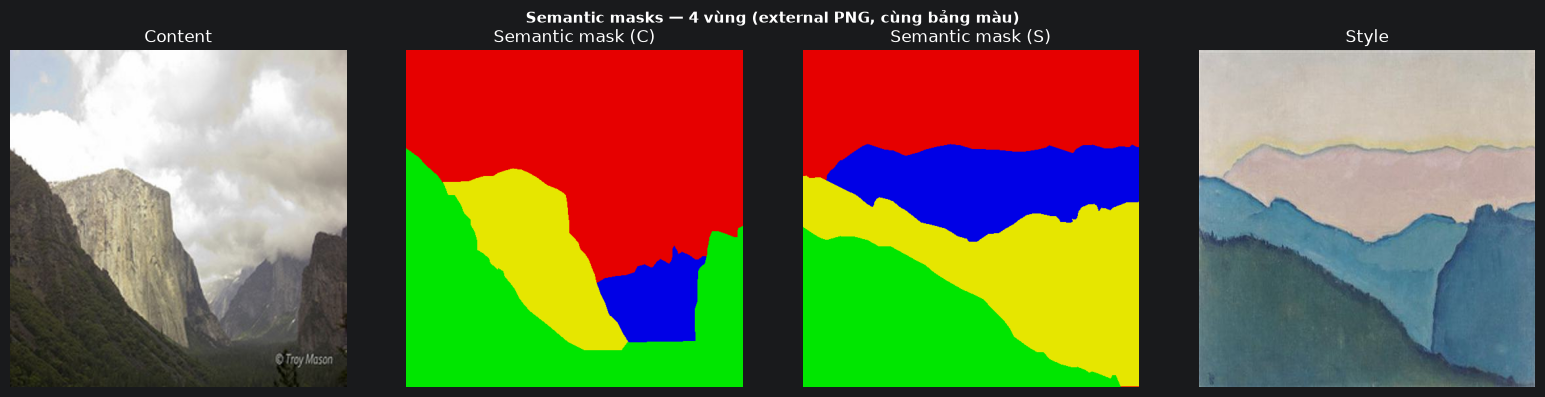

In [160]:
from scsa_nst import load_sem_masks, plot_scsa_semantic

SEM_CONTENT = 'img/yosemite_sem.png'
SEM_STYLE   = 'img/yosemite_paint_sem.png'

# Hiển thị masks ngữ nghĩa (do người dùng cung cấp)
labels_c, labels_s, N_CLUSTERS = load_sem_masks(
    SEM_CONTENT, SEM_STYLE,
)
print(f'Số vùng ngữ nghĩa: {N_CLUSTERS}')
print(f'Labels content unique: {labels_c.unique().tolist()}')
print(f'Labels style   unique: {labels_s.unique().tolist()}')

# Visualise masks bên cạnh ảnh gốc
from PIL import Image
import matplotlib.pyplot as plt, numpy as np

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(Image.open(CONTENT_IMG));          axes[0].set_title('Content');           axes[0].axis('off')
axes[1].imshow(Image.open(SEM_CONTENT));          axes[1].set_title('Semantic mask (C)'); axes[1].axis('off')
axes[2].imshow(Image.open(SEM_STYLE));            axes[2].set_title('Semantic mask (S)'); axes[2].axis('off')
axes[3].imshow(Image.open(STYLE_IMG));            axes[3].set_title('Style');             axes[3].axis('off')
fig.suptitle(f'Semantic masks — {N_CLUSTERS} vùng (external PNG, cùng bảng màu)',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('img/yosemite_fig_scsa_seg.png', dpi=150, bbox_inches='tight')
plt.show()


[SCSA | MPS]  K=4  α₁=0.70  α₂=0.30  sem=external PNG+VGGenc  | 472.9 ms  | Peak RAM: 0 MB


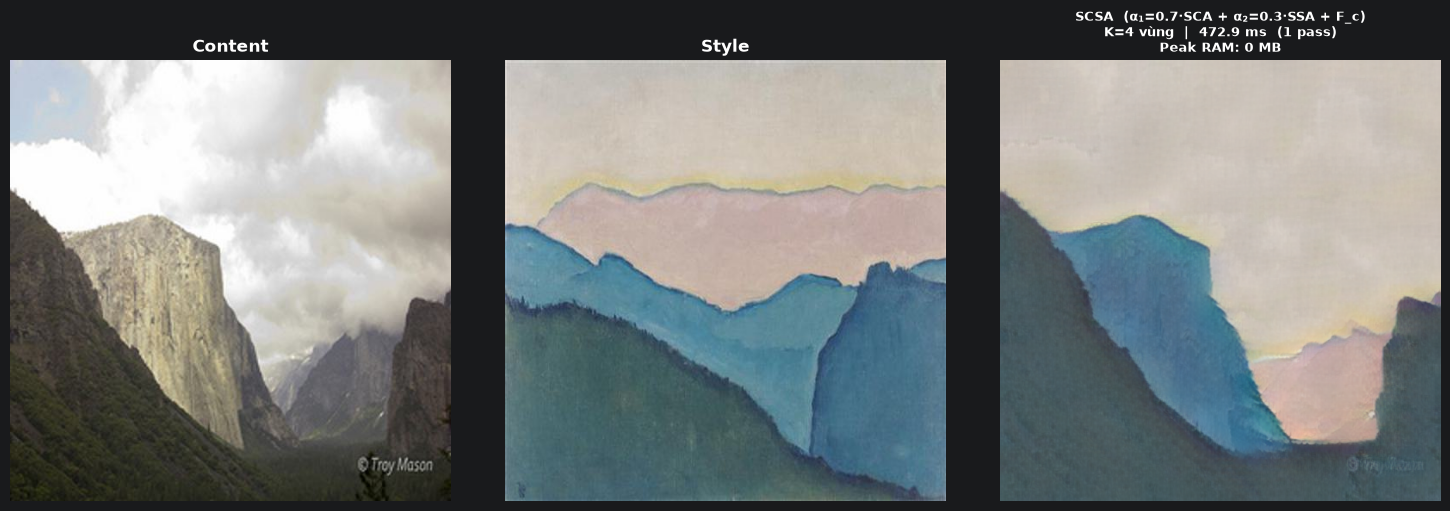

In [161]:
from scsa_nst import run_scsa, plot_scsa_analysis
import os

SEM_MAP_64 = 'sem_precomputed_feats/yosemite/yosemite_yosemite_paint_map_64.pt'
SEM_MAP_32 = 'sem_precomputed_feats/yosemite/yosemite_yosemite_paint_map_32.pt'

result_scsa = run_scsa(
    content_path = CONTENT_IMG,
    style_path   = STYLE_IMG,
    img_size     = 512,
    n_clusters   = N_CLUSTERS,
    alpha1       = 0.7,
    alpha2       = 0.3,
    device       = device,
    sem_content  = SEM_CONTENT,
    sem_style    = SEM_STYLE,
    sem_map_64   = SEM_MAP_64,
    sem_map_32   = SEM_MAP_32,
)
result_scsa.output_image.save('img/yosemite_out_scsa.jpg')

plot_scsa_analysis(
    CONTENT_IMG, STYLE_IMG, result_scsa,
    save_path = 'img/yosemite_fig_scsa.png',
)
benchmark_records.append({
    'Phương pháp'   : 'SCSA (ours)',
    'Thời gian (ms)': round(result_scsa.inference_time_sec * 1000, 1),
    'Peak RAM (MB)' : round(result_scsa.peak_memory_mb, 0),
    'Feed-forward'  : '✓',
    'Semantic-aware': '✓',
    'Ghi chú'       : f'K={N_CLUSTERS} α₁=0.7·SCA + α₂=0.3·SSA | SANet+SCSA dual-level',
})


[SCSA | MPS]  K=4  α₁=0.00  α₂=0.00  sem=external PNG+VGGenc  | 294.4 ms  | Peak RAM: 0 MB
[SCSA | MPS]  K=4  α₁=1.00  α₂=0.00  sem=external PNG+VGGenc  | 292.2 ms  | Peak RAM: 0 MB
[SCSA | MPS]  K=4  α₁=0.00  α₂=1.00  sem=external PNG+VGGenc  | 296.7 ms  | Peak RAM: -16 MB
[SCSA | MPS]  K=4  α₁=0.70  α₂=0.30  sem=external PNG+VGGenc  | 296.2 ms  | Peak RAM: 0 MB
[SCSA | MPS]  K=4  α₁=0.50  α₂=0.50  sem=external PNG+VGGenc  | 293.4 ms  | Peak RAM: 0 MB


/Users/bibeo/Desktop/SCSA/scsa_nst.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  Backbone: VGG-19 normalised encoder + AdaIN decoder (naoto0804 weights).


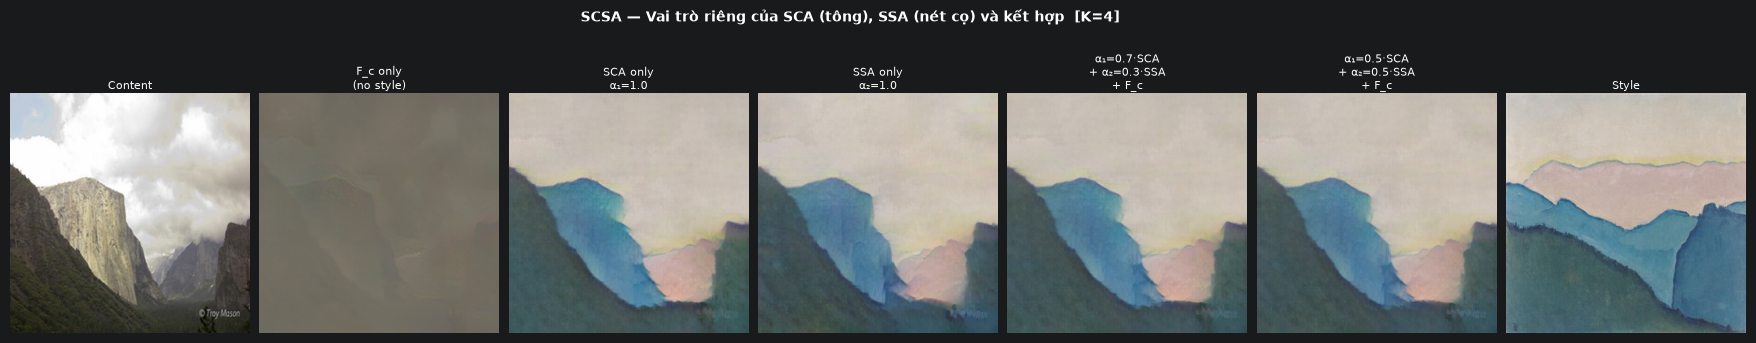

In [162]:
from scsa_nst import plot_scsa_alpha_grid

# Grid α: vai trò riêng của SCA vs SSA (dùng external sem mask)
plot_scsa_alpha_grid(
    CONTENT_IMG, STYLE_IMG,
    alpha_pairs = [
        (0.0, 0.0),   # chỉ F_c
        (1.0, 0.0),   # chỉ SCA (tông màu)
        (0.0, 1.0),   # chỉ SSA (nét cọ)
        (0.7, 0.3),   # blend mặc định
        (0.5, 0.5),   # balanced
    ],
    n_clusters  = N_CLUSTERS,
    img_size    = 256,
    device      = device,
    save_path   = 'img/yosemite_fig_scsa_alpha.png',
    sem_content = SEM_CONTENT,
    sem_style   = SEM_STYLE,
)


---
## 📊 Benchmark tổng hợp

> Bảng này tự cập nhật khi các cell trên chạy xong.
> Mỗi `run_*()` đẩy kết quả vào `benchmark_records`.


In [163]:
# Normalize: đổi BenchmarkResult dataclass → dict (nếu có)
import dataclasses
benchmark_records = [
    dataclasses.asdict(r) if dataclasses.is_dataclass(r) else r
    for r in benchmark_records
]

import pandas as pd

df = pd.DataFrame(benchmark_records)

# Đặt thứ tự cột
cols = ['Phương pháp','Thời gian (ms)','Peak RAM (MB)','Feed-forward','Semantic-aware','Ghi chú']
df = df[[c for c in cols if c in df.columns]]

display(df.style
    .set_caption('📊 So sánh tổng hợp các phương pháp Neural Style Transfer')
    .set_table_styles([{'selector':'caption','props':[('font-size','16px'),('font-weight','bold'),('text-align','left')]}])
    .format({'Thời gian (ms)': '{:.1f}', 'Peak RAM (MB)': '{:.0f}'})
    .hide(axis='index')
)

# Tốc độ tương đối so với Gatys
if len(df) > 1:
    ref = df['Thời gian (ms)'].iloc[0]
    print('\n📈 Tốc độ tương đối (so với Gatys L-BFGS):')
    for _, row in df.iterrows():
        ratio = ref / row['Thời gian (ms)']
        print(f"  {row['Phương pháp']:30s} : {ratio:6.0f}×")

Phương pháp,Thời gian (ms),Peak RAM (MB),Feed-forward,Semantic-aware,Ghi chú
Gatys (LBFGS),26813.7,2156,✗,✗,300 steps
Gatys (ADAM),25115.0,2156,✗,✗,300 steps
AdaIN (α=1.0),96.9,1124,✓,✗,1 forward pass
SANet,124.3,0,✓,✗,SANet (dual-lvl TRAINED)
SCSA (ours),472.9,0,✓,✓,K=4 α₁=0.7·SCA + α₂=0.3·SSA | SANet+SCSA dual-level



📈 Tốc độ tương đối (so với Gatys L-BFGS):
  Gatys (LBFGS)                  :      1×
  Gatys (ADAM)                   :      1×
  AdaIN (α=1.0)                  :    277×
  SANet                          :    216×
  SCSA (ours)                    :     57×


## 📝 Tổng kết

| Phương pháp | Tốc độ | Chất lượng | Semantic | Ứng dụng |
|---|---|---|---|---|
| **Gatys** | ⭐ (chậm) | ⭐⭐⭐ | ✗ | Nghiên cứu, reference |
| **AdaIN** | ⭐⭐⭐⭐⭐ | ⭐⭐ | ✗ | Real-time app |
| **SANet** | ⭐⭐⭐⭐⭐ | ⭐⭐⭐ | ✗ | Chất lượng cao, nhanh |
| **SCSA**  | ⭐⭐⭐⭐⭐ | ⭐⭐⭐⭐ | **✓** | Semantic-aware, plug-and-play |

**SCSA** = SANet + semantic mask. Zero tham số mới, không train lại.
Cải thiện chính: không loang lổ giữa vùng, giữ nét cọ riêng từng ngữ nghĩa.
